In [1]:
!pip install pymoo matplotlib -q

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [3]:
class FrotaRobosProblem(ElementwiseProblem):

    def __init__(self):
        super().__init__(
            n_var=2,
            n_obj=2,
            n_ieq_constr=1,
            xl=np.array([5.0, 1.0]),
            xu=np.array([50.0, 4.0])
        )

    def _evaluate(self, x, out, *args, **kwargs):

        numero_robos = x[0]
        velocidade = x[1]

        # Objetivo 1: Minimizar custo
        f1_custo = (numero_robos * 25.0) + (velocidade ** 2 * 8.0)

        # Objetivo 2: Minimizar tempo médio de ciclo
        f2_tempo = (120.0 / numero_robos) + (40.0 / velocidade)

        # Restrição: consumo energético máximo de 120
        consumo = numero_robos * (velocidade ** 1.5)

        g1 = consumo - 120.0

        out["F"] = [f1_custo, f2_tempo]
        out["G"] = [g1]


print("Problema de frota de robôs criado com sucesso!")

Problema de frota de robôs criado com sucesso!


In [4]:
res7 = minimize(
    FrotaRobosProblem(),
    NSGA2(pop_size=40),
    termination=('n_gen', 60),
    seed=7
)

print("Otimização da frota de robôs concluída!")

Otimização da frota de robôs concluída!


In [5]:
# Filtrar soluções que respeitam a restrição energética
consumo = res7.X[:, 0] * (res7.X[:, 1] ** 1.5)

mask = consumo <= 120.0 + 1e-6

X = res7.X[mask]
F = res7.F[mask]

if len(F) == 0:
    raise ValueError("Nenhuma solução viável encontrada.")

# Menor custo
idx_custo = np.argmin(F[:, 0])

# Menor tempo
idx_tempo = np.argmin(F[:, 1])

# Solução intermediária
amplitude = np.ptp(F, axis=0)
amplitude[amplitude == 0] = 1

normalizado = (F - F.min(axis=0)) / amplitude

distancias = np.linalg.norm(normalizado, axis=1)

idx_intermediario = np.argmin(distancias)

solucoes = [
    ("MENOR CUSTO", idx_custo),
    ("MENOR TEMPO", idx_tempo),
    ("SOLUÇÃO INTERMEDIÁRIA", idx_intermediario)
]

print("RESULTADOS DO EXERCÍCIO 7")
print("=" * 50)

for nome, idx in solucoes:

    robos = X[idx, 0]
    velocidade = X[idx, 1]

    custo = F[idx, 0]
    tempo = F[idx, 1]

    consumo = robos * (velocidade ** 1.5)

    print(f"\n{nome}")
    print(f"Quantidade de robôs: {robos:.2f}")
    print(f"Velocidade: {velocidade:.2f} m/s")
    print(f"Custo: R$ {custo:.2f} mil")
    print(f"Tempo médio: {tempo:.2f} minutos")
    print(f"Consumo energético: {consumo:.2f}")
    print("Status: VIÁVEL")

RESULTADOS DO EXERCÍCIO 7

MENOR CUSTO
Quantidade de robôs: 5.00
Velocidade: 1.00 m/s
Custo: R$ 133.02 mil
Tempo médio: 63.96 minutos
Consumo energético: 5.01
Status: VIÁVEL

MENOR TEMPO
Quantidade de robôs: 16.62
Velocidade: 3.74 m/s
Custo: R$ 527.02 mil
Tempo médio: 17.93 minutos
Consumo energético: 119.97
Status: VIÁVEL

SOLUÇÃO INTERMEDIÁRIA
Quantidade de robôs: 6.46
Velocidade: 2.99 m/s
Custo: R$ 233.17 mil
Tempo médio: 31.94 minutos
Consumo energético: 33.45
Status: VIÁVEL


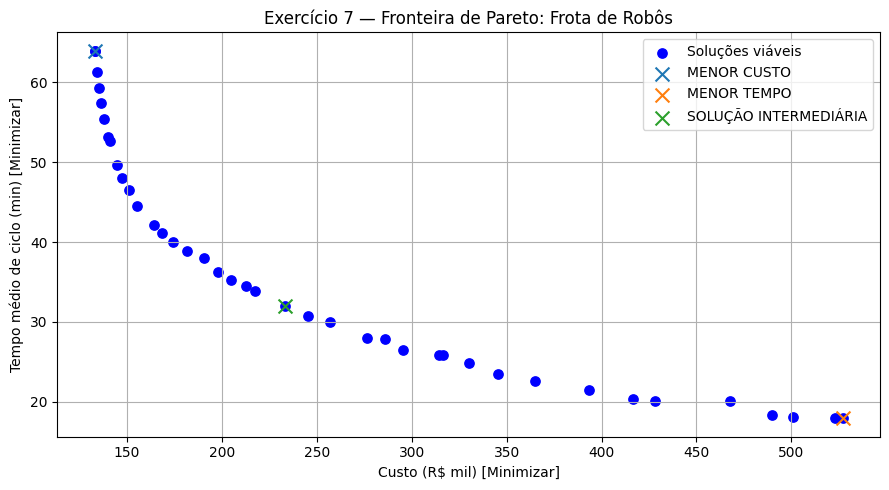

Gráfico salvo com sucesso!


In [6]:
plt.figure(figsize=(9, 5))

plt.scatter(
    F[:, 0],
    F[:, 1],
    color='blue',
    s=45,
    label='Soluções viáveis'
)

for nome, idx in solucoes:
    plt.scatter(
        F[idx, 0],
        F[idx, 1],
        s=100,
        marker='x',
        label=nome
    )

plt.title("Exercício 7 — Fronteira de Pareto: Frota de Robôs")
plt.xlabel("Custo (R$ mil) [Minimizar]")
plt.ylabel("Tempo médio de ciclo (min) [Minimizar]")

plt.grid(True)
plt.legend()
plt.tight_layout()

plt.savefig(
    "fronteira_pareto_frota_robos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico salvo com sucesso!")